# Phase 2: E-Commerce Sales Data Analysis

Exploratory data analysis on the `sales_fact` table built in Phase 1.

**Prerequisites:** Run `python scripts/run_pipeline.py` first to load data into MySQL.

## 1. Connect & Load

In [24]:
import os
import sys
from pathlib import Path
from urllib.parse import quote_plus

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from dotenv import load_dotenv
from sqlalchemy import text

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "scripts") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
load_dotenv(PROJECT_ROOT / ".env", override=True)

from db_utils import fetch_monthly_revenue, get_connection, get_engine

engine = get_engine()

df = pd.read_sql(text("SELECT * FROM sales_fact"), engine)
print(f"Loaded {len(df):,} rows from sales_fact")
df.head()

Loaded 110,197 rows from sales_fact


,order_id,order_item_id,order_date,customer_location,customer_state,product_id,product_category,price,quantity,total_revenue,payment_type,delivery_time_days
0,00010242fe8c5a6d1ba2dd792cb16214,1,2017-09-13,"campos dos goytacazes, RJ",RJ,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,58.90,1,72.19,credit_card,7.0
1,00018f77f2f0320c557190d7a144bdd3,1,2017-04-26,"santa fe do sul, SP",SP,e5f2d52b802189ee658865ca93d83a8f,pet_shop,239.90,1,259.83,credit_card,16.0
2,000229ec398224ef6ca0657da4fc703e,1,2018-01-14,"para de minas, MG",MG,c777355d18b72b67abbeef9df44fd0fd,furniture_decor,199.00,1,216.87,credit_card,8.0
3,00024acbcdf0a6daa1e931b038114c75,1,2018-08-08,"atibaia, SP",SP,7634da152a4610f1595efa32f14722fc,perfumery,12.99,1,25.78,credit_card,6.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,2017-02-04,"varzea paulista, SP",SP,ac6c3623068f30de03045865e4e10089,garden_tools,199.90,1,218.04,credit_card,25.0


## 2. Data Type Conversion

In [25]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["price"] = pd.to_numeric(df["price"], errors="coerce")
df["total_revenue"] = pd.to_numeric(df["total_revenue"], errors="coerce")
df["delivery_time_days"] = pd.to_numeric(df["delivery_time_days"], errors="coerce")

df.dtypes

order_id                        str
order_item_id                 int64
order_date            datetime64[s]
customer_location               str
customer_state                  str
product_id                      str
product_category                str
price                       float64
quantity                      int64
total_revenue               float64
payment_type                    str
delivery_time_days          float64
dtype: object

## 3. Time Aggregations (Day / Week / Month)

In [26]:
daily_sales = (
    df.groupby("order_date")
    .agg(revenue=("total_revenue", "sum"), orders=("order_id", "nunique"))
    .reset_index()
)
daily_sales["aov"] = daily_sales["revenue"] / daily_sales["orders"]

weekly_sales = (
    df.set_index("order_date")
    .resample("W")
    .agg(revenue=("total_revenue", "sum"), orders=("order_id", "nunique"))
)
weekly_sales["aov"] = weekly_sales["revenue"] / weekly_sales["orders"]

monthly_sales = (
    df.set_index("order_date")
    .resample("ME")
    .agg(revenue=("total_revenue", "sum"), orders=("order_id", "nunique"))
)
monthly_sales["aov"] = monthly_sales["revenue"] / monthly_sales["orders"]

print("Daily (last 5 rows):")
display(daily_sales.tail())
print("\nMonthly:")
display(monthly_sales)

Daily (last 5 rows):


,order_date,revenue,orders,aov
607,2018-08-25,11737.76,69,170.112464
608,2018-08-26,9333.16,73,127.851507
609,2018-08-27,6111.61,66,92.600152
610,2018-08-28,4121.22,39,105.672308
611,2018-08-29,1762.70,11,160.245455



Monthly:


,revenue,orders,aov
order_date,,,
2016-09-30,143.46,1,143.460000
2016-10-31,46490.66,265,175.436453
2016-11-30,0.00,0,NaN
2016-12-31,19.62,1,19.620000
2017-01-31,127482.37,750,169.976493
2017-02-28,271239.32,1653,164.089123
2017-03-31,414330.95,2546,162.738001
2017-04-30,390812.40,2303,169.697091
2017-05-31,566851.40,3546,159.856571


In [27]:
data_dir = PROJECT_ROOT / "data"
data_dir.mkdir(exist_ok=True)
monthly_sales.reset_index().to_csv(data_dir / "monthly_revenue.csv", index=False)
print(f"Exported monthly series to {data_dir / 'monthly_revenue.csv'}")

Exported monthly series to d:\E-commerce Sales forecasting\data\monthly_revenue.csv


## 4. EDA — Sales Trend Over Time

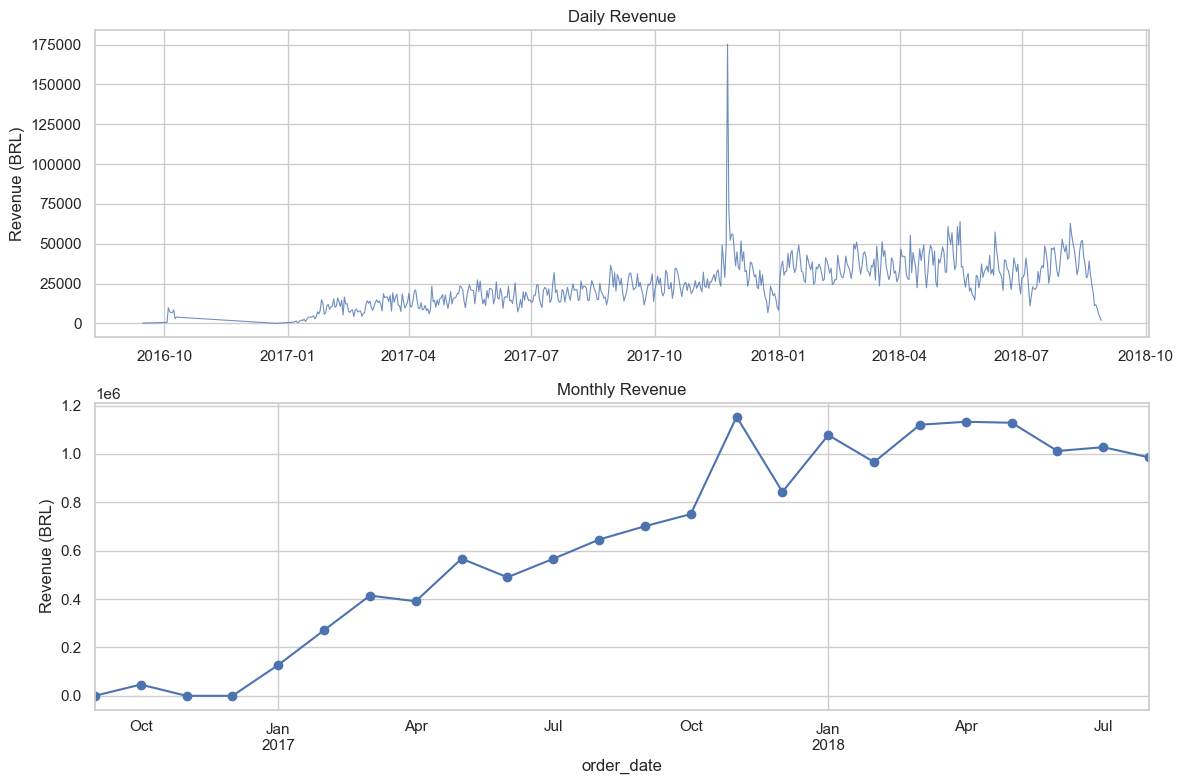

Date range: 2016-09-15 to 2018-08-29


In [28]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(daily_sales["order_date"], daily_sales["revenue"], linewidth=0.8, alpha=0.8)
axes[0].set_title("Daily Revenue")
axes[0].set_ylabel("Revenue (BRL)")

monthly_sales.plot(y="revenue", ax=axes[1], marker="o", legend=False)
axes[1].set_title("Monthly Revenue")
axes[1].set_ylabel("Revenue (BRL)")

plt.tight_layout()
plt.show()

print(
    f"Date range: {df['order_date'].min().date()} to {df['order_date'].max().date()}"
)

## 4b. EDA — Seasonality Patterns

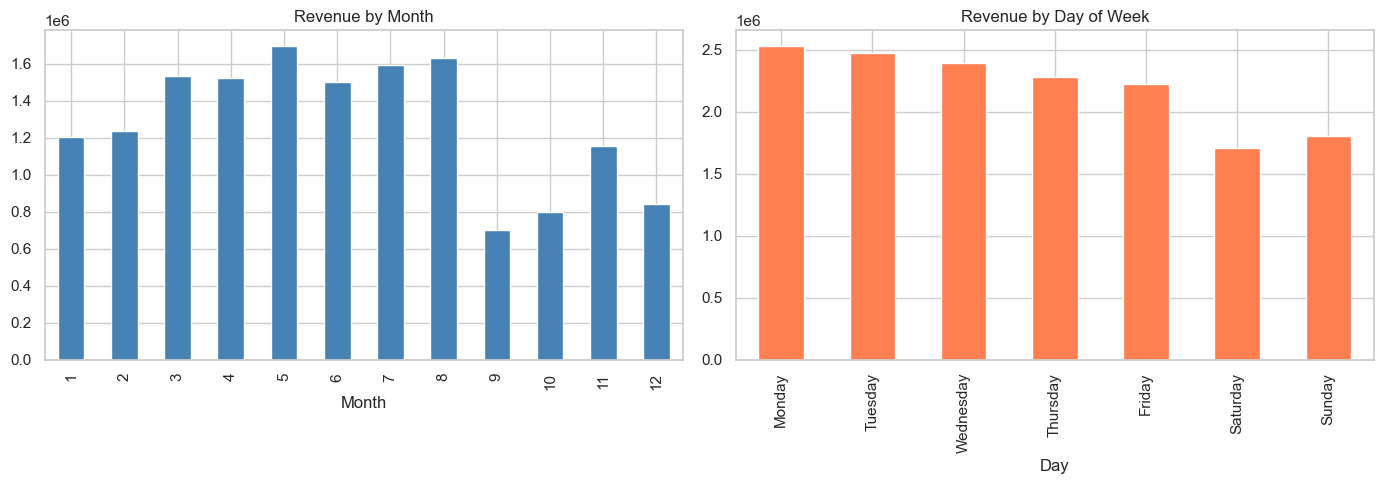

In [29]:
df["month"] = df["order_date"].dt.month
df["day_of_week"] = df["order_date"].dt.day_name()

month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
monthly_pattern = df.groupby("month")["total_revenue"].sum()

dow_pattern = (
    df.groupby("day_of_week")["total_revenue"].sum()
    .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
monthly_pattern.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Revenue by Month")
axes[0].set_xlabel("Month")

dow_pattern.plot(kind="bar", ax=axes[1], color="coral")
axes[1].set_title("Revenue by Day of Week")
axes[1].set_xlabel("Day")

plt.tight_layout()
plt.show()

## 4c. EDA — Category Performance

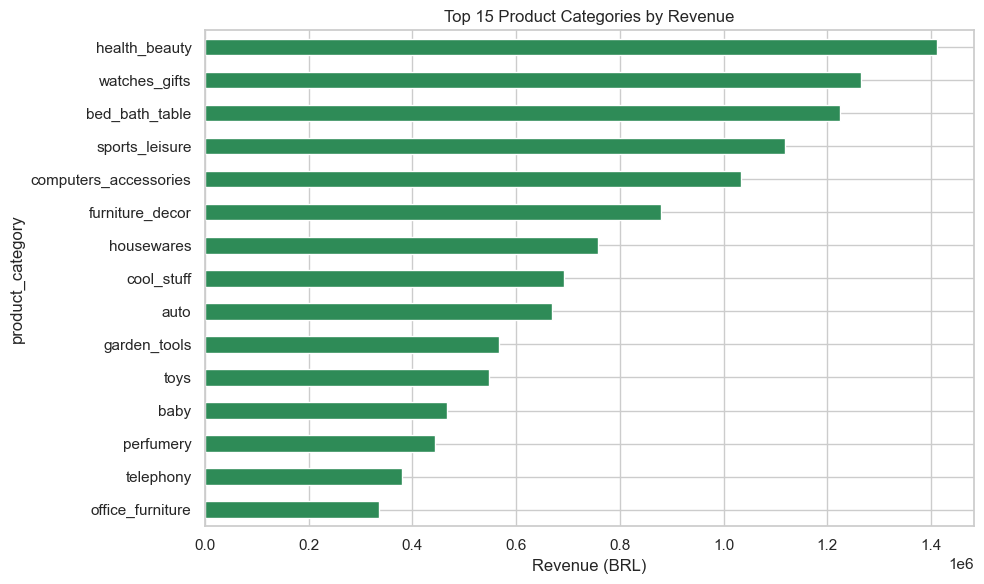

In [30]:
category_revenue = (
    df.groupby("product_category")["total_revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(10, 6))
category_revenue.plot(kind="barh", ax=ax, color="seagreen")
ax.set_title("Top 15 Product Categories by Revenue")
ax.set_xlabel("Revenue (BRL)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 4d. EDA — Region-Based Sales

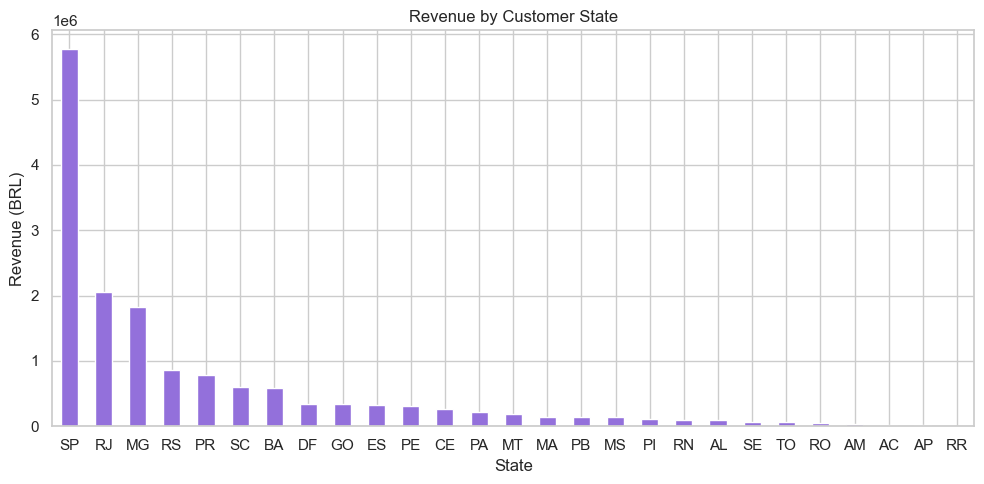

Top state: SP (R$ 5,769,703.15)


In [31]:
state_revenue = (
    df.groupby("customer_state")["total_revenue"]
    .sum()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 5))
state_revenue.plot(kind="bar", ax=ax, color="mediumpurple")
ax.set_title("Revenue by Customer State")
ax.set_xlabel("State")
ax.set_ylabel("Revenue (BRL)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"Top state: {state_revenue.index[0]} (R$ {state_revenue.iloc[0]:,.2f})")

## 5. Summary Statistics

In [32]:
repeat_rate = pd.read_sql(
    """
    SELECT ROUND(
        100.0 * SUM(CASE WHEN order_count > 1 THEN 1 ELSE 0 END) / COUNT(*), 2
    ) AS repeat_customer_pct
    FROM (
        SELECT c.customer_unique_id, COUNT(DISTINCT o.order_id) AS order_count
        FROM stg_orders o
        JOIN stg_customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
        GROUP BY c.customer_unique_id
    ) t
    """,
    get_connection(),
)["repeat_customer_pct"].iloc[0]

summary = {
    "Date range": f"{df['order_date'].min().date()} to {df['order_date'].max().date()}",
    "Total revenue (BRL)": f"{df['total_revenue'].sum():,.2f}",
    "Total orders": f"{df['order_id'].nunique():,}",
    "Overall AOV (BRL)": f"{df['total_revenue'].sum() / df['order_id'].nunique():,.2f}",
    "Top category": category_revenue.index[0],
    "Top state": state_revenue.index[0],
    "Avg delivery time (days)": f"{df['delivery_time_days'].mean():.1f}",
    "Repeat customer rate (%)": f"{repeat_rate}",
}

for key, value in summary.items():
    print(f"{key}: {value}")

C:\Users\DELL\AppData\Local\Temp\ipykernel_22324\3476265172.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  repeat_rate = pd.read_sql(


Date range: 2016-09-15 to 2018-08-29
Total revenue (BRL): 15,419,773.75
Total orders: 96,478
Overall AOV (BRL): 159.83
Top category: health_beauty
Top state: SP
Avg delivery time (days): 12.4
Repeat customer rate (%): 3.0


## 6. Cross-Validation — Python vs SQL Monthly Revenue

In [33]:
sql_monthly = fetch_monthly_revenue()
sql_monthly["monthly_revenue"] = sql_monthly["monthly_revenue"].astype(float)

python_monthly = monthly_sales.copy()
python_monthly = python_monthly.reset_index()
python_monthly["year_month"] = python_monthly["order_date"].dt.strftime("%Y-%m")
python_monthly["monthly_revenue"] = python_monthly["revenue"].round(2)

comparison = sql_monthly.merge(
    python_monthly[["year_month", "monthly_revenue"]],
    on="year_month",
    suffixes=("_sql", "_python"),
)
comparison["diff"] = (
    comparison["monthly_revenue_sql"] - comparison["monthly_revenue_python"]
).abs()

display(comparison)
assert comparison["diff"].max() < 0.01, "Monthly totals do not match SQL Query #2!"
print("Cross-validation PASSED: Python monthly totals match SQL Query #2.")

,year_month,monthly_revenue_sql,monthly_revenue_python,diff
0,2016-09,143.46,143.46,0.0
1,2016-10,46490.66,46490.66,0.0
2,2016-12,19.62,19.62,0.0
3,2017-01,127482.37,127482.37,0.0
4,2017-02,271239.32,271239.32,0.0
5,2017-03,414330.95,414330.95,0.0
6,2017-04,390812.40,390812.40,0.0
7,2017-05,566851.40,566851.40,0.0
8,2017-06,490050.37,490050.37,0.0
9,2017-07,566299.08,566299.08,0.0


Cross-validation PASSED: Python monthly totals match SQL Query #2.


## 8. Anomaly Detection

Detect **sudden spikes and drops** in daily revenue using two simple methods:

| Method | Idea | When it helps |
|--------|------|----------------|
| **Z-score** | Compare each day to the global mean ± std dev | Quick baseline; flags extreme days |
| **Rolling deviation** | Compare each day to a 7-day rolling mean ± std dev | Adapts as sales grow over time |

A day is flagged if **either** method exceeds a threshold (|z| > 2).

Anomalies: 18 days (15 spikes, 3 drops)


,order_date,revenue,orders,z_score,rolling_z,pct_from_rolling,anomaly_type
333,2017-11-24,175178.46,1147,10.436873,2.223397,213.535459,spike
334,2017-11-25,70683.26,487,3.165349,0.162903,13.679485,spike
506,2018-05-16,63957.96,351,2.697355,1.240611,30.200939,spike
588,2018-08-06,62728.22,363,2.611781,1.864809,29.622504,spike
497,2018-05-07,60805.36,363,2.477974,1.812700,42.813713,spike
504,2018-05-14,60753.87,355,2.474391,1.250382,27.225821,spike
532,2018-06-11,57313.28,294,2.234970,2.043056,52.537550,spike
500,2018-05-10,56936.61,273,2.208759,0.848426,20.685773,spike
337,2017-11-28,55990.30,372,2.142908,-0.286563,-19.756876,drop
336,2017-11-27,55887.39,395,2.135747,-0.230682,-16.930846,drop


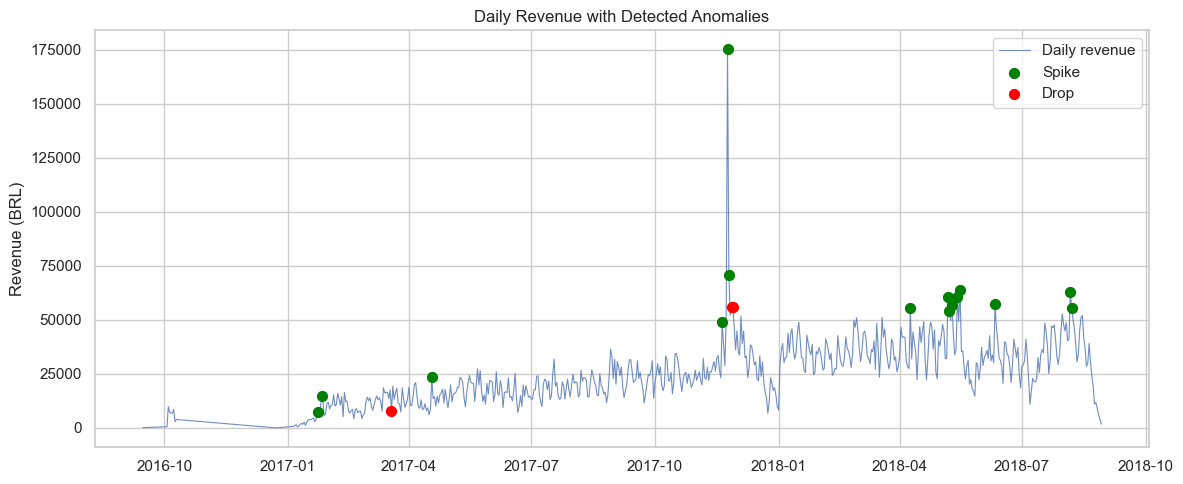

Saved d:\E-commerce Sales forecasting\data\daily_anomalies.csv


In [34]:
import numpy as np

Z_THRESHOLD = 2.0
ROLLING_WINDOW = 7

anomaly_df = daily_sales.copy().sort_values("order_date").reset_index(drop=True)

#Method 1: Global z-score
mean_rev = anomaly_df["revenue"].mean()
std_rev = anomaly_df["revenue"].std()
anomaly_df["z_score"] = (anomaly_df["revenue"] - mean_rev) / std_rev
anomaly_df["is_anomaly_zscore"] = anomaly_df["z_score"].abs() > Z_THRESHOLD

#Method 2: Rolling average deviation
anomaly_df["rolling_mean"] = (
    anomaly_df["revenue"].rolling(ROLLING_WINDOW, min_periods=3).mean()
)
anomaly_df["rolling_std"] = (
    anomaly_df["revenue"].rolling(ROLLING_WINDOW, min_periods=3).std()
)
anomaly_df["rolling_z"] = (
    (anomaly_df["revenue"] - anomaly_df["rolling_mean"]) / anomaly_df["rolling_std"]
)
anomaly_df["pct_from_rolling"] = (
    (anomaly_df["revenue"] - anomaly_df["rolling_mean"]) / anomaly_df["rolling_mean"] * 100
)
anomaly_df["is_anomaly_rolling"] = anomaly_df["rolling_z"].abs() > Z_THRESHOLD

anomaly_df["is_anomaly"] = (
    anomaly_df["is_anomaly_zscore"] | anomaly_df["is_anomaly_rolling"]
)
anomaly_df["anomaly_type"] = np.where(
    ~anomaly_df["is_anomaly"],
    "normal",
    np.where(anomaly_df["revenue"] > anomaly_df["rolling_mean"], "spike", "drop"),
)

top_anomalies = (
    anomaly_df[anomaly_df["is_anomaly"]]
    .assign(abs_z=lambda d: d["z_score"].abs())
    .sort_values("abs_z", ascending=False)
    .head(10)[
        [
            "order_date", "revenue", "orders", "z_score", "rolling_z",
            "pct_from_rolling", "anomaly_type",
        ]
    ]
)

print(
    f"Anomalies: {anomaly_df['is_anomaly'].sum()} days "
    f"({(anomaly_df['anomaly_type'] == 'spike').sum()} spikes, "
    f"{(anomaly_df['anomaly_type'] == 'drop').sum()} drops)"
)
display(top_anomalies)

#Chart: daily revenue with anomaly markers
flagged = anomaly_df[anomaly_df["is_anomaly"]]
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(anomaly_df["order_date"], anomaly_df["revenue"], linewidth=0.8, alpha=0.8, label="Daily revenue")
ax.scatter(
    flagged[flagged["anomaly_type"] == "spike"]["order_date"],
    flagged[flagged["anomaly_type"] == "spike"]["revenue"],
    color="green", s=50, zorder=3, label="Spike",
)
ax.scatter(
    flagged[flagged["anomaly_type"] == "drop"]["order_date"],
    flagged[flagged["anomaly_type"] == "drop"]["revenue"],
    color="red", s=50, zorder=3, label="Drop",
)
ax.set_title("Daily Revenue with Detected Anomalies")
ax.set_ylabel("Revenue (BRL)")
ax.legend()
plt.tight_layout()
plt.show()

#Export for reporting / daily pipeline
anomaly_df.to_csv(PROJECT_ROOT / "data" / "daily_anomalies.csv", index=False)
print(f"Saved {PROJECT_ROOT / 'data' / 'daily_anomalies.csv'}")

### Business interpretation

- **Spikes** often align with seasonal peaks (e.g. November holiday shopping in Brazil).
- **Drops** in early 2016–2017 may reflect low platform volume, not operational issues.
- For production, run `python scripts/detect_anomalies.py` after each daily data refresh.

---

## 9. Data Pipeline Thinking

**Question:** *If new data comes daily, how will the system update?*

```mermaid
flowchart LR
    newCSV[New CSV in datasets/incremental] --> loadInc[load_incremental.py]
    loadInc --> staging[MySQL staging tables]
    staging --> fact[validate_sql.py rebuilds sales_fact]
    fact --> anomalies[detect_anomalies.py]
    fact --> forecast[data/monthly_revenue.csv]
    anomalies --> alert[Spike/drop report]
    forecast --> powerbi[Power BI / Phase 3 forecast]
```

| Trigger | Command | Result |
|---------|---------|--------|
| First-time setup | `python scripts/run_pipeline.py` | Full CSV load + fact table |
| Daily refresh | `python scripts/run_daily_pipeline.py` | Append new rows → rebuild fact → anomaly check → export |

**Key design choices:**
1. **Append to staging** — new order CSVs land in `datasets/incremental/` with the same filenames.
2. **Rebuild `sales_fact`** — simplest way to keep dimensions and joins consistent (no partial-update bugs).
3. **Primary keys** — duplicate `order_id` rows are rejected, so re-running the same file is safe.
4. **Scheduler** — Windows Task Scheduler or cron runs `run_daily_pipeline.py` every morning.

Full architecture: see [docs/DATA_PIPELINE.md](../docs/DATA_PIPELINE.md).

## 10. Data Quality Notes

- **Delivered orders only** — canceled and in-transit orders are excluded from `sales_fact`.
- **Quantity = 1** per line item — Olist dataset has no quantity column; each `order_items` row represents one unit.
- **Total revenue** = `price + freight_value` per line item.
- **NULL categories** mapped to `'unknown'` during Phase 1 dimension build.
- **Geolocation table** was not loaded — region analysis uses `customer_state` and `customer_city` from the customers table.